# 04 — So sánh kết quả Data Preprocessing

Notebook đối chiếu ba nguồn dữ liệu thực từ summary/report đã sinh. Notebook không đọc nối các run, không chạy lại pipeline và không tạo thay đổi đối với Parquet hoặc raw data.

## 1. Thiết lập và dữ liệu tham chiếu

Các số liệu được đọc từ đường dẫn repository-relative `ml/reports/preprocessing/preprocessing_summary.json`; hình được đọc từ thư mục artifact đã gitignore.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tìm repository root để notebook chạy từ thư mục gốc hoặc thư mục con.
def find_repo_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "ml/preprocessing").is_dir() and (candidate / "ml/reports/preprocessing/preprocessing_summary.json").is_file():
            return candidate
    raise FileNotFoundError("Không tìm thấy repository SVMG hoặc báo cáo preprocessing.")

ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SUMMARY_PATH = ROOT / "ml/reports/preprocessing/preprocessing_summary.json"
summary = json.loads(SUMMARY_PATH.read_text(encoding="utf-8"))
CONFIG_PATH = ROOT / "ml/preprocessing/config.yaml"
from ml.preprocessing.config import load_config
config = load_config(CONFIG_PATH)
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.unicode_minus": False, "figure.autolayout": True})

def repo_relative(path):
    candidate = Path(path)
    if candidate.is_absolute():
        try:
            candidate = candidate.resolve().relative_to(ROOT)
        except ValueError:
            # Hỗ trợ summary cũ từ clone khác bằng cách lấy phần bắt đầu tại ml/.
            parts = candidate.parts
            if "ml" not in parts:
                raise
            candidate = Path(*parts[parts.index("ml"):])
    return (ROOT / candidate).resolve().relative_to(ROOT).as_posix()

dataset_names = ["seafar", "hohai", "southampton"]


## 2. Tổng quan phiên, thời lượng, Sampling Rate và window eligibility

Gap count bằng 0 của Hohai chỉ phản ánh timeline suy từ sample index theo 50 Hz, không chứng minh sensor không dropout.

In [2]:
rows = []
for dataset in dataset_names:
    item = summary["datasets"][dataset]
    rows.append({
        "Nguồn": dataset.capitalize(), "Phiên": item["session_count"], "Segment đầu ra": item["segments_output"],
        "Hàng trước": item["rows_before"], "Hàng sau": item["rows_after"],
        "Sampling Rate đầu vào median (Hz)": item["sampling_rate_before_hz_median"],
        "Sampling Rate đầu ra median (Hz)": item["sampling_rate_after_hz_median"],
        "Gap quan sát được": item["gap_count"], "Đủ 60 s": item["eligible_60s_segments"],
        "Đủ 180 s": item["eligible_180s_segments"],
        "Gyro X": item["gyro_availability"]["gyro_x_rad_s"], "Gyro Y": item["gyro_availability"]["gyro_y_rad_s"],
        "Thời lượng trước (s)": item["duration_before_cumulative_seconds"],
        "Thời lượng sau (s)": item["duration_after_cumulative_seconds"],
    })
comparison_summary = pd.DataFrame(rows)
display(comparison_summary)


,Nguồn,Phiên,Segment đầu ra,Hàng trước,Hàng sau,Sampling Rate đầu vào median (Hz),Sampling Rate đầu ra median (Hz),Gap quan sát được,Đủ 60 s,Đủ 180 s,Gyro X,Gyro Y,Thời lượng trước (s),Thời lượng sau (s)
0,Seafar,1,24,143318,143264,10.00001,10.0,31,7,4,AVAILABLE,AVAILABLE,14332.60,14324.0
1,Hohai,21,21,944998,188580,50.00000,10.0,0,21,21,UNAVAILABLE,UNAVAILABLE,18899.54,18855.9
2,Southampton,47,47,274317,53942,50.00000,10.0,0,47,1,UNAVAILABLE,UNAVAILABLE,5485.40,5389.5


## 3. So sánh thống kê Roll/Pitch trước và sau

Bảng đọc giá trị thống kê thực từ summary pipeline, không tính lại toàn bộ raw data.

In [3]:
test_results = summary["test_results"]
print("Kết quả kiểm thử preprocessing ghi trong báo cáo:")
display(pd.DataFrame([{"Tổng bài": test_results["total"], "Đạt": test_results["passed"],
    "Không đạt": test_results["failed"], "Bỏ qua": test_results["skipped"],
    "Lệnh": test_results["command"], "Kết quả": test_results["result_summary"]}]))


Kết quả kiểm thử preprocessing ghi trong báo cáo:


,Tổng bài,Đạt,Không đạt,Bỏ qua,Lệnh,Kết quả
0,18,18,0,0,python -m pytest ml/preprocessing/tests -q,18 passed in 1.62s


In [4]:
rows = []
for dataset in dataset_names:
    item = summary["datasets"][dataset]
    for signal, label in (("roll_deg", "Roll (độ)"), ("pitch_deg", "Pitch (độ)")):
        before, after = item["statistics_before"][signal], item["statistics_after"][signal]
        rows.append({"Nguồn": dataset.capitalize(), "Tín hiệu": label,
            "Mean trước": before["mean"], "Mean sau": after["mean"],
            "Độ lệch chuẩn trước": before["std_population"], "Độ lệch chuẩn sau": after["std_population"],
            "RMS trước": before["rms"], "RMS sau": after["rms"],
            "P05 trước": before["p05"], "P05 sau": after["p05"],
            "P95 trước": before["p95"], "P95 sau": after["p95"]})
display(pd.DataFrame(rows).style.format(precision=5))


,Nguồn,Tín hiệu,Mean trước,Mean sau,Độ lệch chuẩn trước,Độ lệch chuẩn sau,RMS trước,RMS sau,P05 trước,P05 sau,P95 trước,P95 sau
0,Seafar,Roll (độ),3.31319,3.31318,0.23509,0.23509,3.32152,3.32151,2.96000,2.96000,3.70000,3.70000
1,Seafar,Pitch (độ),0.84008,0.84005,0.10874,0.10874,0.84708,0.84706,0.65000,0.65000,1.00000,1.00000
2,Hohai,Roll (độ),0.01411,0.01410,0.36249,0.36272,0.36277,0.36300,-0.57000,-0.56959,0.62000,0.61790
3,Hohai,Pitch (độ),0.00154,0.00155,0.08836,0.08818,0.08837,0.08819,-0.15000,-0.14148,0.15000,0.14479
4,Southampton,Roll (độ),0.37825,0.37842,0.28263,0.28288,0.47218,0.47246,-0.03922,-0.03988,0.83460,0.83441
5,Southampton,Pitch (độ),0.56586,0.56801,1.18773,1.19053,1.31564,1.31909,-1.19489,-1.20055,2.06998,2.07970


## 4. So sánh lọc và resampling

Tỷ lệ công suất dải thấp gần 1 biểu thị năng lượng dải 0,1–2 Hz được giữ tương đối; suy giảm ngoài dải âm biểu thị giảm năng lượng 5,25 Hz đến Nyquist nguồn. Đây là diagnostics, không phải ngưỡng an toàn.

In [5]:
rows = []
for dataset in dataset_names:
    records = summary["datasets"][dataset]["frequency_diagnostics"]
    for signal, label in (("roll_deg", "Roll"), ("pitch_deg", "Pitch")):
        values = [record[signal] for record in records if record.get(signal)]
        if values:
            rows.append({"Nguồn": dataset.capitalize(), "Tín hiệu": label,
                "Segment đo": len(values), "Giữ dải thấp median": float(np.median([x["low_band_power_ratio"] for x in values])),
                "Suy giảm ngoài dải median (dB)": float(np.median([x["out_of_band_attenuation_db"] for x in values]))})
        elif dataset == "seafar":
            rows.append({"Nguồn": dataset.capitalize(), "Tín hiệu": label, "Segment đo": 0,
                "Giữ dải thấp median": np.nan, "Suy giảm ngoài dải median (dB)": np.nan})
display(pd.DataFrame(rows).style.format(precision=5, na_rep="Không áp dụng"))


,Nguồn,Tín hiệu,Segment đo,Giữ dải thấp median,Suy giảm ngoài dải median (dB)
0,Seafar,Roll,0,Không áp dụng,Không áp dụng
1,Seafar,Pitch,0,Không áp dụng,Không áp dụng
2,Hohai,Roll,21,0.99991,-24.68960
3,Hohai,Pitch,21,0.99995,-23.74751
4,Southampton,Roll,47,0.99764,-16.26507
5,Southampton,Pitch,47,0.99979,-24.55024


## 5. Hình chẩn đoán thực nghiệm

Các hình được nạp từ output thật của pipeline: Roll/Pitch raw và processed, gaps, phân bố tín hiệu, PSD và Nyquist. Chúng được tạo riêng theo các session đại diện; không chứa bảng raw đầy đủ.

So sánh tín hiệu Roll trước và sau tiền xử lý; dữ liệu đại diện theo từng nguồn.


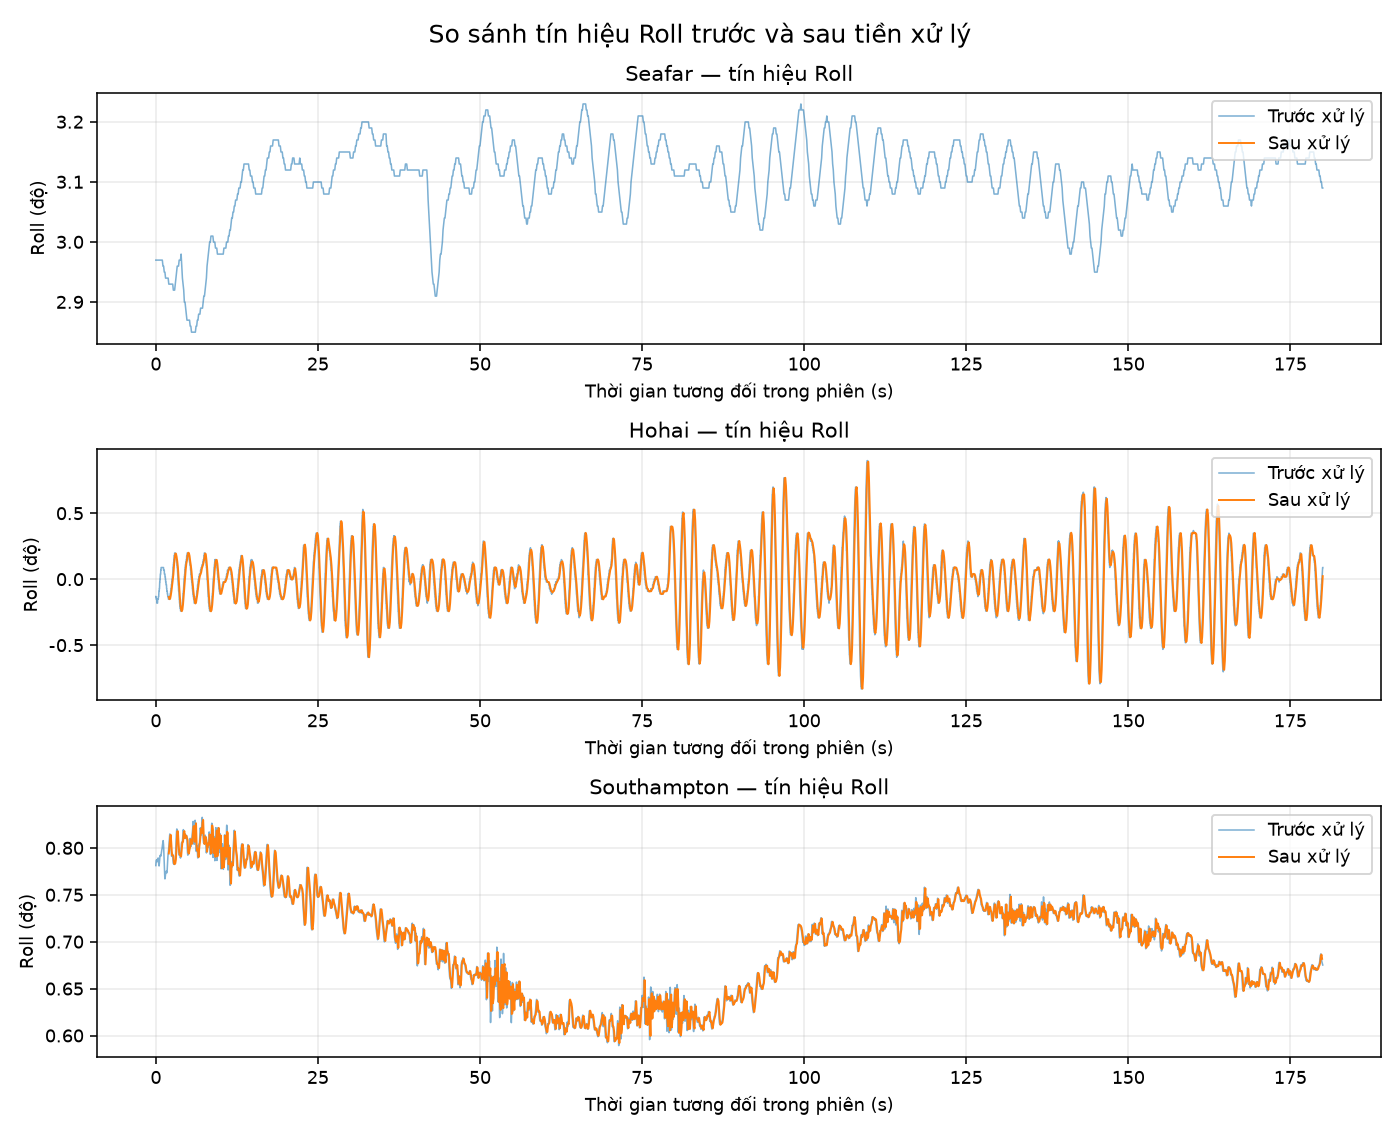

So sánh tín hiệu Pitch trước và sau tiền xử lý; dữ liệu đại diện theo từng nguồn.


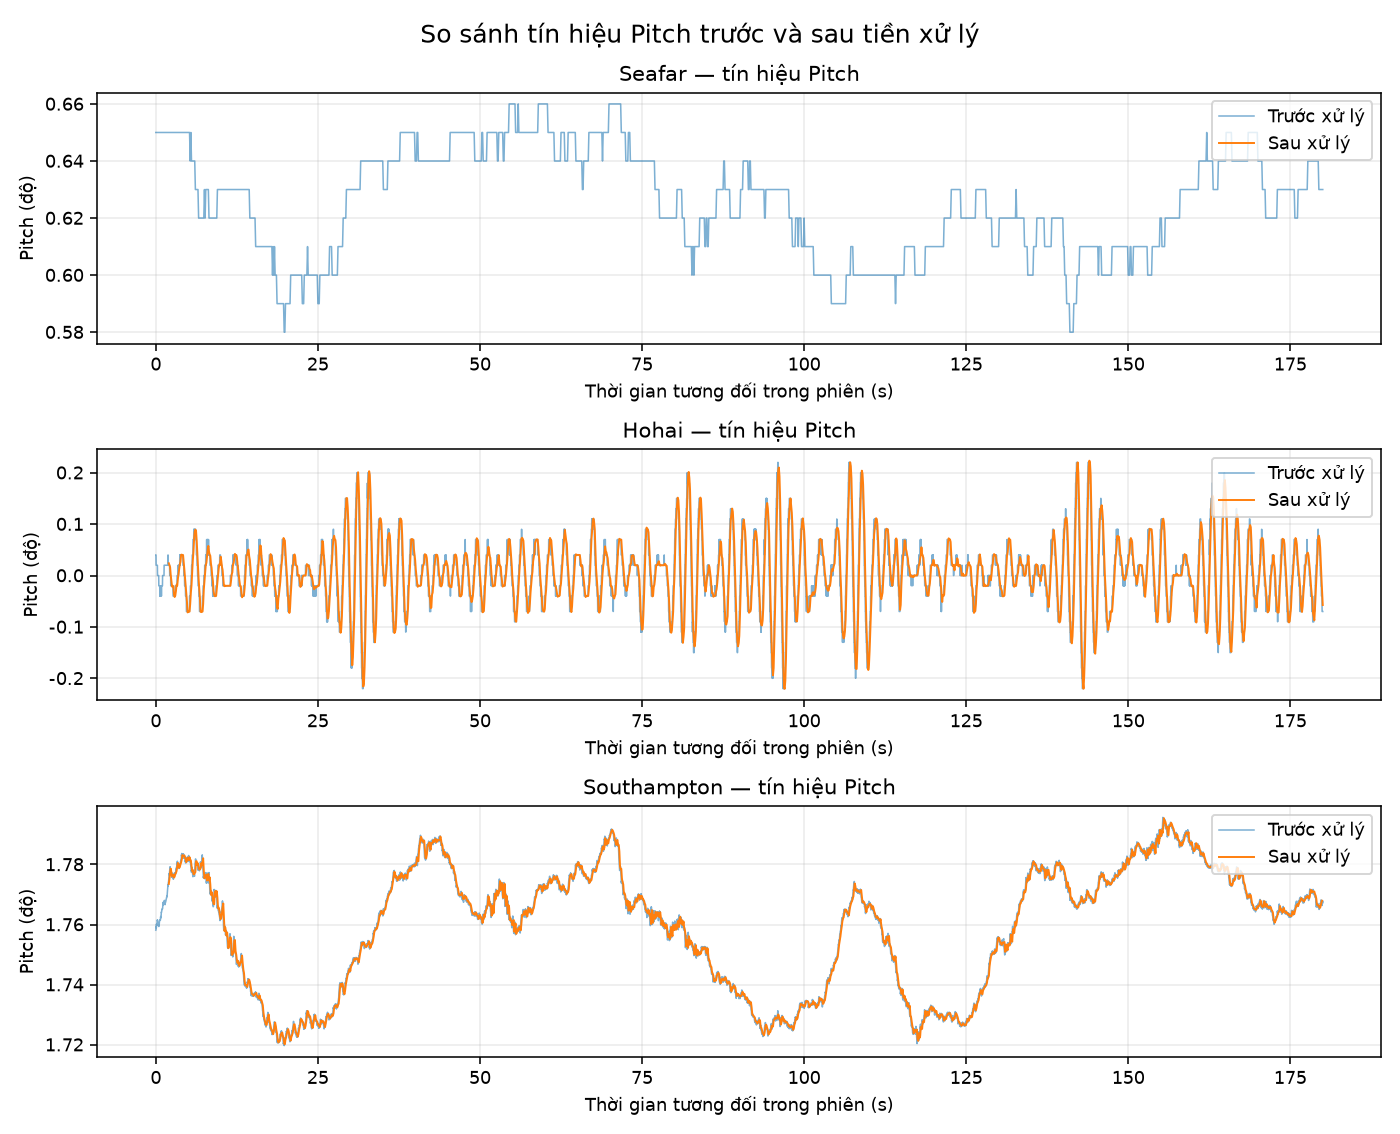

Khoảng cách timestamp trên dữ liệu đầu vào; đường ngang biểu thị ngưỡng gap của cấu hình.


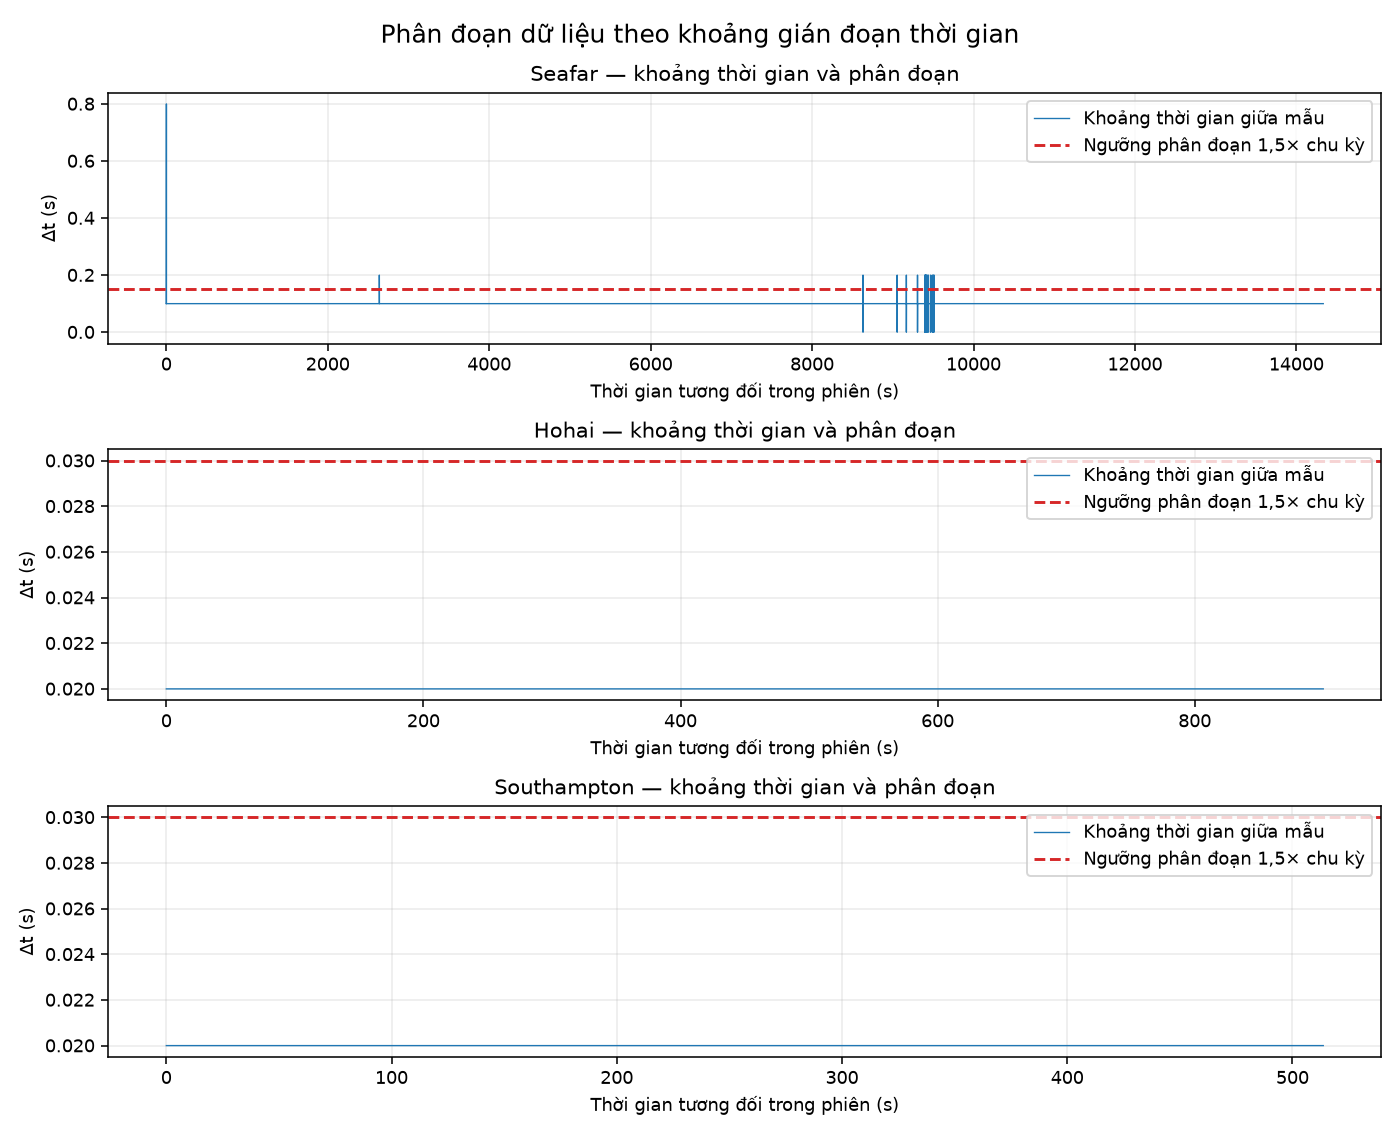

Phân bố Roll/Pitch trước xử lý và sau xử lý; histogram mô tả biến đổi do lọc/lấy mẫu.


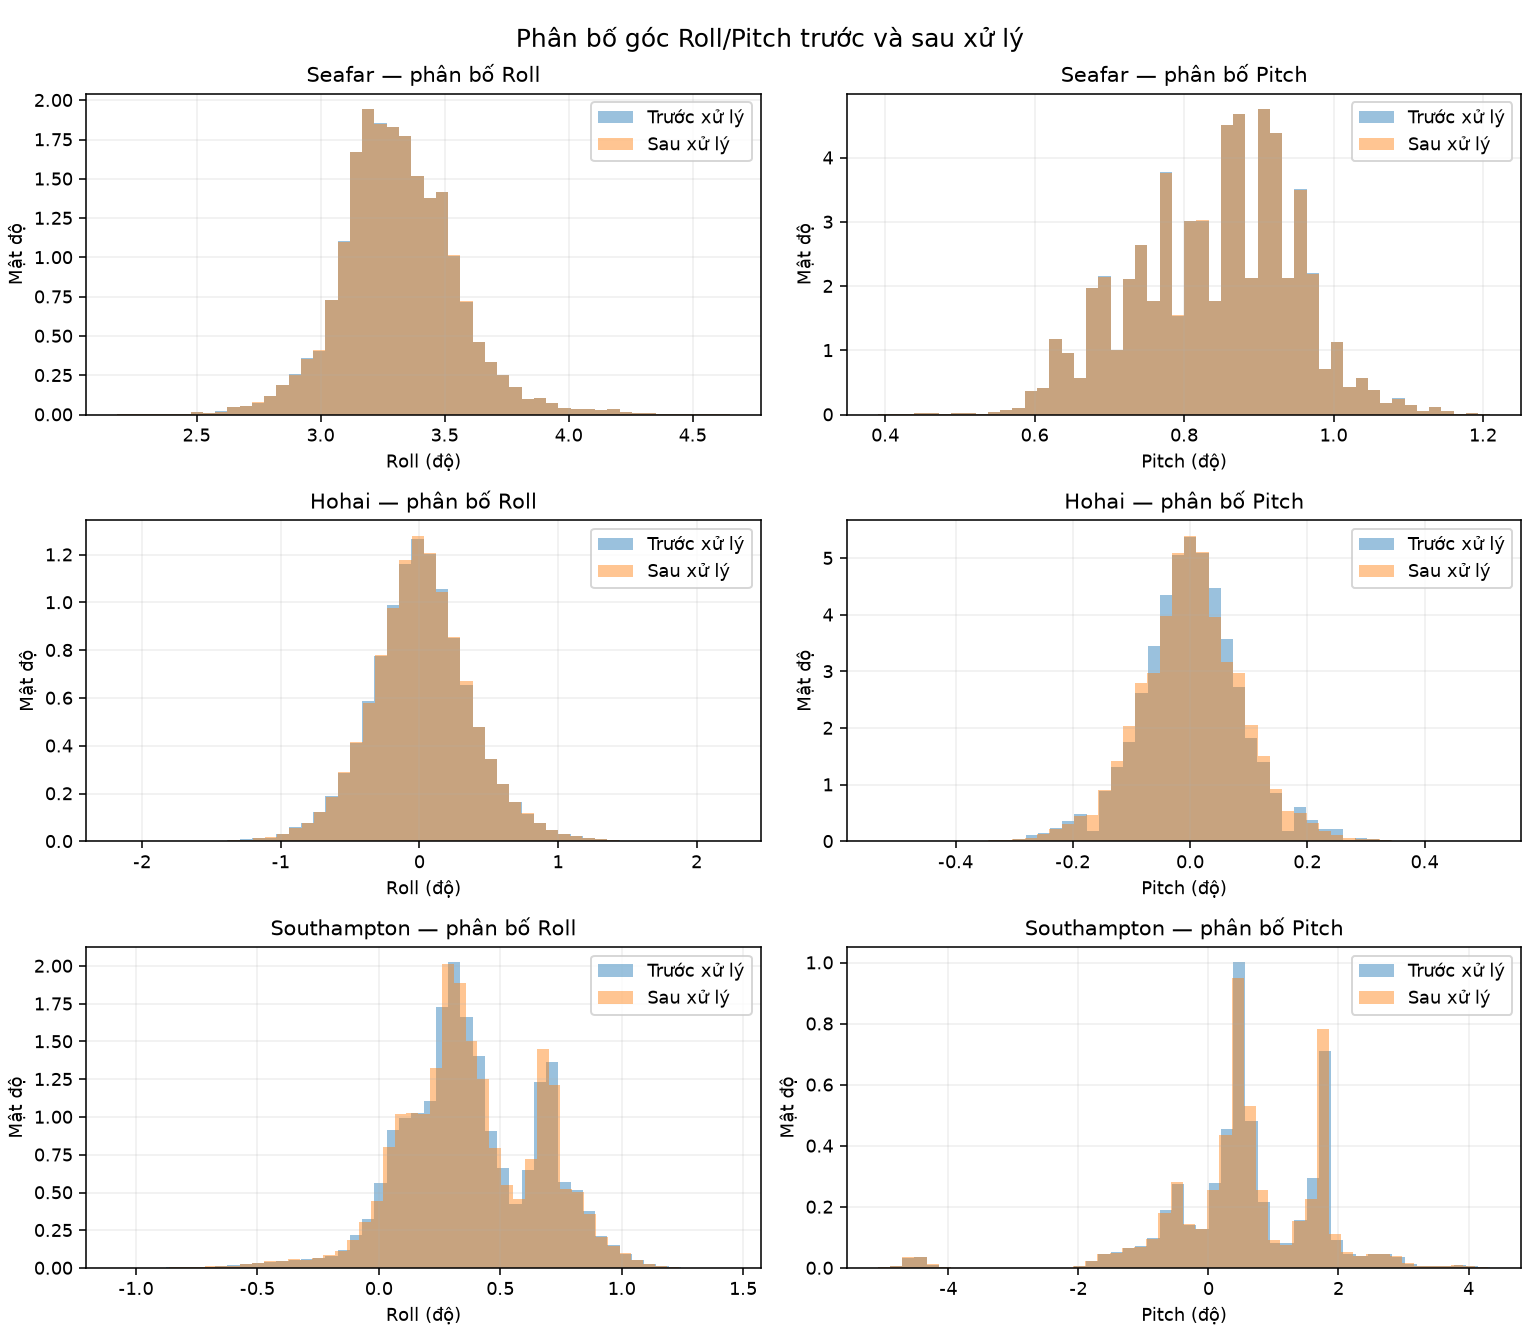

Mật độ phổ công suất trước/sau; đường Nyquist cho lưới đầu ra.


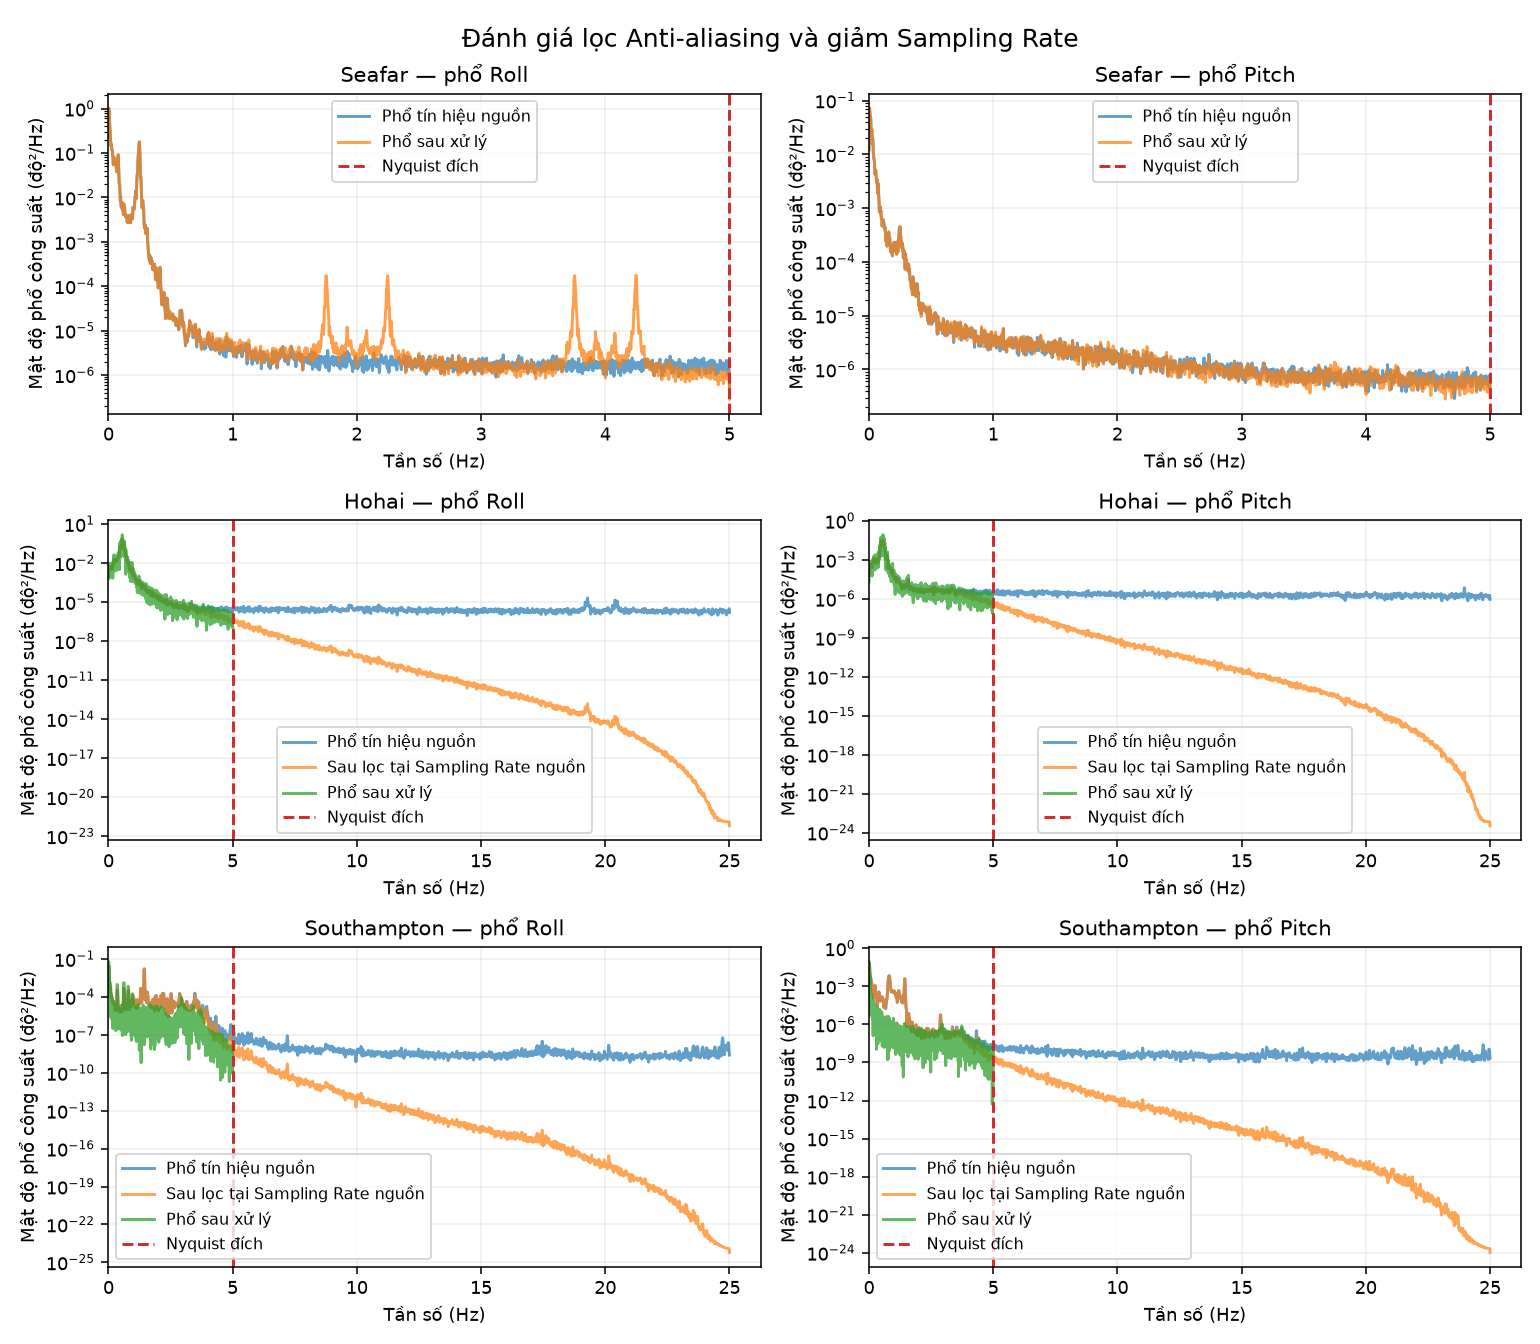

In [6]:
from IPython.display import Image
for item in summary["figures"]:
    figure_path = ROOT / repo_relative(item["path"])
    print(item["caption_vi"])
    display(Image(filename=str(figure_path), width=900))


## Giải thích kỹ thuật phục vụ vấn đáp

- **Em đã làm gì?** Tổng hợp số liệu từ `preprocessing_summary.json`, bảng so sánh thống kê và các hình đã được tạo bởi pipeline.
- **Vì sao?** Ba dataset khác nhau về Sampling Rate, timestamp, unit và độ dài phiên; so sánh giúp thấy giới hạn dữ liệu trước Feature Extraction.
- **Phương pháp?** So sánh số hàng, số phiên/segment, thời lượng, window eligibility, trạng thái gyro, thống kê Roll/Pitch và band-power anti-alias. Notebook không chạy lại hay thay đổi preprocessing.
- **Kết quả thực tế?** Seafar có 7/4 phiên-segment đủ 60/180 s; Hohai 21/21; Southampton 47/1. Các số liệu chi tiết được trình bày ở trên và phải khớp với báo cáo.
- **Nếu bỏ qua?** Có thể so sánh không tương đương hoặc cho rằng mọi run đủ cửa sổ dài.
- **Giới hạn?** Thống kê mô tả không chứng minh tính đại diện; Hohai continuity suy luận, Southampton chỉ một run đủ 180 s, gyro canonical thiếu ở hai nguồn.

## Kết luận có điều kiện

Các artifact hiện đủ để nghiên cứu Feature Extraction theo từng session/segment và theo dõi missing channel. Cần nhóm xác nhận unit/trục gyro Seafar, ngữ nghĩa Delta Angle, giả định timestamp Hohai, target 10 Hz/cutoff trước khi chốt thiết kế. Không có nhãn hoặc kết quả mô hình trong phạm vi notebook này.


## 6. Tái lập

Từ repository root, cài dependencies của preprocessing/notebook rồi chạy từng notebook bằng lệnh `python -m jupyter nbconvert --to notebook --execute --inplace ml/notebooks/01_seafar_preprocessing.ipynb` (thay tên notebook tương ứng). Lệnh không gọi lại pipeline; để tái tạo Parquet/báo cáo, dùng lệnh CLI trong `ml/preprocessing/README.md`.